**Note for reviewers.** This notebook also contains analyses that are not reported in the paper: its legacy scrub section and its steering-geometry section. Those sections are kept only so the notebook runs as one unit, and their outputs should not be read as paper results.

# New wd=0.1 benchmark follow-up (execution preparation)
Exploratory validation analysis; historical saved outputs cleared.
Historical numerical prose is background, not a result of this benchmark.
Output-key scrubbing does not establish a serial algorithm. MB16 legacy scrub results
are invalidated by F25; use Section R corrected results. No new test access is permitted.


# MB16 — A Corrected Causal Scrub, and Why the Identity Direction Steers So Strongly

**Track B · Follow-up to MB11b, MB11c and MB12 · Identity × Context project**

| Item | Content |
|---|---|
| **Questions** | (1) MB11b wrote the same donor activation into both the run with the player and the run without it, which forces the identity effect to the floor whatever the mechanism. With donors drawn separately for each run, does a stated mechanism keep the identity effect, and does a mechanism that ignores the player lose it? (2) Is the leading identity direction of MB11c special, or does it steer strongly because it lines up with the direction the output reads? (3) Would a calibration model that follows the measured response have predicted the steering numbers that MB12's straight line missed? |
| **Population** | P-player validation. Donor pool: all P-player validation events. Scrub measured on the estimation half; subspaces from the discovery half. |
| **Status** | Follow-up after MB12; exploratory; not part of the MB12 lock. Hypotheses and plan are written and fingerprinted before any number. No test data. |
| **Outputs** | `config/MB16_plan.json`, `results/MB16_*` |

> **⚠ REPAIR STATUS (2026-10-04) — new finding F25, not in the MB01–MB13 review.**
> MB16 fixed MB11b's same-donor defect by drawing donors **independently for each run**. That makes each event's scrubbed
> identity effect the difference of two unrelated donors' Δ values (several nats apart), while the true effect is about
> 0.17 nats. The floor is then mostly noise, and the sign-aligned recovered share Σ sign(full − floor)(scrub − floor) /
> Σ |full − floor| is pushed towards 1 by that noise whatever the scrub does. The saved table shows it: permuted labels 0.990,
> every wrong-class control 0.906–0.998, and H1c 0.832 although H1c's mean identity effect has the **opposite sign** to the
> intact model's (+0.788 vs −0.171). **Every identity-effect recovered share in Sections 4 and 8 is therefore INVALIDATED
> (measurement design)**, and so are the comparisons built on them. The **arbitration** (Δ) rows are not affected in the same
> way, because Δ ≈ 6 nats per event is large relative to that noise.
> **F06** also applies to Section 5's `steer()` (batch-mean scale). Sections 9–10 use a fixed unit and are unaffected.
>
> **Section R** demonstrates the artifact directly (two independent floor draws score each other as ≈ 100% recovery). It then
> re-runs MB16's coarse and action-label hypotheses with paired counterfactual donors (`src/scrub.py`; H1–H3 are run in
> MB11b Section R5) and re-runs Section 5's steering with a frozen scale.

In [1]:
import os
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: False | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified_at_start = fingerprint.verify_files(MANIFEST)
manifest_before = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
assert IDENTITY == "player", "BLOCKED: MB14-MB16 follow up MB04-MB12, which studied the player variable."
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])


SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_DRAWS = SETTINGS["n_draws"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
# No test view is built or read anywhere in MB14-MB16 (mi_setup.unlock_test_view is never called).
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
ALL = circuits.all_components(N_LAYERS, N_HEADS)
FEATURES = list(bundle["encoded"].tensors.keys())
IDENTITY_FEATURES = [name for name in ["player", "team", "role", "competition"] if name in FEATURES]
CONTEXT_FEATURES = [name for name in FEATURES if name not in IDENTITY_FEATURES]

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
print(f"verified files: {len(verified_at_start)} | primary seed {PRIMARY_SEED} | seeds {SEEDS}")
print(f"P-player rows: {len(p_player):,} (discovery {len(discovery):,}, estimation {len(estimation):,}) | "
      f"index-0: {len(index0):,} | matched controls: {len(controls):,}")
print(f"components: {ALL}")
print(f"identity inputs: {IDENTITY_FEATURES} | context inputs ({len(CONTEXT_FEATURES)}): {CONTEXT_FEATURES}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 86 | primary seed 103 | seeds [100, 101, 102, 103, 104]
P-player rows: 1,744 (discovery 1,215, estimation 529) | index-0: 8,947 | matched controls: 252
components: ['L0H0', 'L0H1', 'L0MLP', 'L1H0', 'L1H1', 'L1MLP', 'L2H0', 'L2H1', 'L2MLP', 'L3H0', 'L3H1', 'L3MLP']
identity inputs: ['player', 'team', 'role', 'competition'] | context inputs (15): ['zone', 'period', 'minute_bin', 'score_diff', 'play_pattern', 'poss_len', 'possession_flag', 'prev_action', 'prev_outcome', 'prev_end_zone', 'same_player_as_prev', 'x_norm', 'y_norm', 'dt', 't_poss']


## 1. What was wrong with MB11b's scrub, and the corrected design

The identity effect is a difference of two runs: Δ on the event as recorded minus Δ with the player removed. Causal scrubbing replaces a component's output by its output on another input that the hypothesis says the component cannot tell apart from this one. That other input has to be drawn **for each run separately**: in the run with the player removed, the equivalent inputs are those whose own player is also removed. MB11b drew one donor and wrote its recorded activation into both runs, so every scrubbed component gave the same output in both, and the player could reach the output only through the direct path (3% of the effect). The scrub could therefore not retain the identity effect under any hypothesis.

**Corrected design.** The donor dataset is every P-player validation event in two versions: as recorded, and with the player removed at the scored position. Each version carries its own class labels (the removed version has player = 0) and its own cached activations. For each event and each run, each component's donor is drawn from the dataset entries in the same class as **that run's** input, excluding both versions of the event itself. Components the hypothesis declares irrelevant are drawn from the whole dataset, independently for each run. Scrubbing acts at the scored position, where MB06 found both effects.

## 2. Hypotheses and plan (written before any number)

| Hypothesis | MLP outputs depend only on | Heads | Prediction |
|---|---|---|---|
| **H1 shared chain** | player, role, previous action, possession change, coupled flag | irrelevant (free) | keeps most of the identity effect and of Δ |
| **H2 player-blind chain** | role, previous action, possession change, coupled flag | irrelevant (free) | loses the identity effect, keeps Δ |
| **H3 heads matter** | free | player, role, previous action, possession change, coupled flag | loses both |
| **H1c / H2c (coarse)** | as H1 / H2 without the previous action (H1c: player, possession change, coupled; H2c: role, possession change, coupled) | free | as H1 / H2 for the identity effect; Δ may be lost, because the previous action matters for it (MB13) |

Controls: the floor (every component free), and H1 and H1c with their class labels permuted across the dataset (same class sizes, no meaning). An abstraction is supported only if it beats its permuted-label control.

**Sparse classes.** H1's classes are fine-grained, so some events have no other event in their class; their components keep their own activations, which flatters H1. The fine hypotheses are therefore scored on the events that H1 scrubbed completely (primary) and on all events (secondary). The coarse pair is scored on all events. If fewer than about 200 events are completely scrubbed under H1, read the fine pair as underpowered and rely on the coarse pair.

In [4]:
PLAN = {
    "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
    "scrub_design": "per-run donors from a dataset of every P-player validation event, as recorded and with the player removed; at the scored position",
    "hypotheses": {
        "H1 shared chain": {"MLP class keys": ["player", "role", "prev_action_id", "team_change", "coupled_with_prev"], "heads": "free"},
        "H2 player-blind chain": {"MLP class keys": ["role", "prev_action_id", "team_change", "coupled_with_prev"], "heads": "free"},
        "H3 heads matter": {"MLP class keys": "free", "head class keys": ["player", "role", "prev_action_id", "team_change", "coupled_with_prev"]},
        "H1c shared chain, coarse": {"MLP class keys": ["player", "team_change", "coupled_with_prev"], "heads": "free"},
        "H2c player-blind chain, coarse": {"MLP class keys": ["role", "team_change", "coupled_with_prev"], "heads": "free"}
    },
    "why_coarse": "the fine classes may leave many events without a donor; the coarse pair drops the previous action and is read on all events",
    "controls": ["floor: every component free", "H1 with class labels permuted across the dataset"],
    "measure": "recovered share = pooled sign-aligned (scrub - floor) / (full - floor), for the identity effect and for Delta; estimation half; scrub_draws draws",
    "reading_rule": "an abstraction is supported for a behaviour if its recovered share CI lies above that of its permuted-label control, on the events where H1 found a donor for every component (primary) and on all events (secondary)",
    "steering": ("v1 = leading direction of player-swap contributions at the final residual (discovery half, as MB11c); "
                 "compare v1, v1 with its component along the mean output-gradient direction removed, the mean output-gradient direction, "
                 "and the leading direction of random-vector contributions; beta grid -2..2"),
    "calibration": "fit a straight line and a monotone piecewise-linear interpolation to the discovery-half response; predict the estimation-half response at beta -1, 0.5, 1"
}
plan_path = OUT / "config" / "MB16_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB16_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB16_plan.json
{
 "status": "follow-up after MB12; exploratory; not part of the MB12 lock",
 "scrub_design": "per-run donors from a dataset of every P-player validation event, as recorded and with the player removed; at the scored position",
 "hypotheses": {
  "H1 shared chain": {
   "MLP class keys": [
    "player",
    "role",
    "prev_action_id",
    "team_change",
    "coupled_with_prev"
   ],
   "heads": "free"
  },
  "H2 player-blind chain": {
   "MLP class keys": [
    "role",
    "prev_action_id",
    "team_change",
    "coupled_with_prev"
   ],
   "heads": "free"
  },
  "H3 heads matter": {
   "MLP class keys": "free",
   "head class keys": [
    "player",
    "role",
    "prev_action_id",
    "team_change",
    "coupled_with_prev"
   ]
  },
  "H1c shared chain, coarse": {
   "MLP class keys": [
    "player",
    "team_change",
    "coupled_with_prev"
   ],
   "heads": "free"
  },
  "H2c player-blind chain, coarse": {
   "MLP class keys": [
    "role",
    "team

## 3. The donor dataset and its class sizes

In [5]:
KEYS_FULL = ["player", "role", "prev_action_id", "team_change", "coupled_with_prev"]
KEYS_BLIND = ["role", "prev_action_id", "team_change", "coupled_with_prev"]
KEYS_FULL_COARSE = ["player", "team_change", "coupled_with_prev"]
KEYS_BLIND_COARSE = ["role", "team_change", "coupled_with_prev"]
missing = [key for key in KEYS_FULL if key not in p_player.columns]
assert not missing, f"BLOCKED: the conflict table lacks {missing}"
SCRUB_SITES = sorted({f"head_z_{l}" for l in range(N_LAYERS)} | {f"mlp_out_{l}" for l in range(N_LAYERS)})
HEADS = [c for c in ALL if not c.endswith("MLP")]
MLPS = [c for c in ALL if c.endswith("MLP")]

pool = pd.concat([p_player.assign(version="recorded"),
                  p_player.assign(version="removed", player=0)], ignore_index=True)
pool["event_id"] = np.tile(np.arange(len(p_player)), 2)


@torch.no_grad()
def cache_at_target(table, removed):
    """Each scrub site at the scored position, for every row of `table` (as recorded or player removed)."""
    out = {site: [] for site in SCRUB_SITES}
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        if removed:
            inputs = interventions.remove_feature(inputs, IDENTITY, positions)
        _, cache = hooks.forward(MODEL, inputs, capture=SCRUB_SITES)
        rows = torch.arange(len(positions), device=DEVICE)
        for site in SCRUB_SITES:
            out[site].append(cache[site][rows, positions])
    return {site: torch.cat(values) for site, values in out.items()}


recorded_cache = cache_at_target(p_player, removed=False)
removed_cache = cache_at_target(p_player, removed=True)
POOL_CACHE = {site: torch.cat([recorded_cache[site], removed_cache[site]]) for site in SCRUB_SITES}
for name, keys in [("H1 / H3 keys", KEYS_FULL), ("H2 keys", KEYS_BLIND), ("H1c keys", KEYS_FULL_COARSE), ("H2c keys", KEYS_BLIND_COARSE)]:
    sizes = pool.groupby(keys).size()
    own = pool.groupby(keys)["event_id"].transform("nunique")
    print(f"{name}: {len(sizes)} classes in the donor dataset | median class size {sizes.median():.0f} | "
          f"entries with no other event in their class: {(own == 1).mean():.3f}")

H1 / H3 keys: 1428 classes in the donor dataset | median class size 1 | entries with no other event in their class: 0.237
H2 keys: 410 classes in the donor dataset | median class size 4 | entries with no other event in their class: 0.101
H1c keys: 396 classes in the donor dataset | median class size 4 | entries with no other event in their class: 0.024
H2c keys: 86 classes in the donor dataset | median class size 31 | entries with no other event in their class: 0.006


## 4. The scrub

> **⚠ REPAIR NOTE (2026-10-04) — INVALIDATED — MEASUREMENT DESIGN (identity-effect rows only) — F25.** Independent per-run donors make the per-event floor mostly noise; the identity-effect recovered shares below are near 1 for every scrub, including controls. Arbitration rows: see the note at the top. Corrected: Section R.

In [6]:
def class_index(keys, frame, permutation=None):
    labels = list(map(tuple, frame[keys].to_numpy())) if keys else [0] * len(frame)
    if permutation is not None:
        labels = [labels[i] for i in permutation]
    groups = {}
    for position, label in enumerate(labels):
        groups.setdefault(label, []).append(position)
    return labels, {label: np.asarray(members) for label, members in groups.items()}


def draw_donors(event_ids, query_labels, groups, rng):
    """For each query, a pool entry of the same class from another event; -1 if none exists."""
    donors = np.full(len(event_ids), -1, dtype=np.int64)
    pool_event = pool["event_id"].to_numpy()
    for i, (event, label) in enumerate(zip(event_ids, query_labels)):
        members = groups.get(label)
        if members is None:
            continue
        members = members[pool_event[members] != event]
        if len(members):
            donors[i] = members[rng.integers(len(members))]
    return donors


def scrub_replace(positions, donors_by_component):
    per_site = {}
    for component, donor_rows in donors_by_component.items():
        kind, layer, head = circuits.parse(component)
        site = f"head_z_{layer}" if kind == "head" else f"mlp_out_{layer}"
        index = torch.as_tensor(donor_rows, device=DEVICE)
        keep = index < 0
        source = POOL_CACHE[site][index.clamp(min=0)]

        def edit(value, source=source, keep=keep, head=head):
            new = value.clone()
            rows = torch.arange(value.shape[0], device=value.device)
            current = value[rows, positions]
            chosen = torch.where(keep.view(-1, *([1] * (current.dim() - 1))), current, source)
            if head is None:
                new[rows, positions] = chosen
            else:
                new[rows, positions, head] = chosen[:, head]
            return new
        per_site.setdefault(site, []).append(edit)
    return {site: hooks.combine(*edits) for site, edits in per_site.items()}


def run_scrub(spec, table, draws, seed, permute=False):
    """spec: {component: keys or None (free)}. Returns mean over draws of (Delta recorded, Delta removed)."""
    rng = np.random.default_rng(seed)
    permutation = rng.permutation(len(pool)) if permute else None
    event_index = {row: i for i, row in enumerate(p_player["event_row"])}
    table_events = np.array([event_index[row] for row in table["event_row"]])
    recorded_q = table.copy()
    removed_q = table.assign(player=0)
    labels = {}
    for component, keys in spec.items():
        pool_labels, groups = class_index(keys, pool, permutation)
        query_recorded = list(map(tuple, recorded_q[keys].to_numpy())) if keys else [0] * len(table)
        query_removed = list(map(tuple, removed_q[keys].to_numpy())) if keys else [0] * len(table)
        labels[component] = (groups, query_recorded, query_removed)
    totals = np.zeros((2, len(table)))
    unscrubbed = []
    missing_any = np.zeros(len(table), dtype=bool)
    for _ in range(draws):
        donors = {"recorded": {}, "removed": {}}
        for component, (groups, query_recorded, query_removed) in labels.items():
            donors["recorded"][component] = draw_donors(table_events, query_recorded, groups, rng)
            donors["removed"][component] = draw_donors(table_events, query_removed, groups, rng)
            unscrubbed.append(float(np.mean(donors["recorded"][component] < 0)))
            missing_any |= (donors["recorded"][component] < 0) | (donors["removed"][component] < 0)
        with torch.no_grad():
            for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
                removed_inputs = interventions.remove_feature(inputs, IDENTITY, positions)
                for slot, (run_inputs, run) in enumerate([(inputs, "recorded"), (removed_inputs, "removed")]):
                    replace = scrub_replace(positions, {c: d[part] for c, d in donors[run].items()})
                    totals[slot, part] += circuits.delta_under(MODEL, run_inputs, positions, a_ctx, a_id, replace) / draws
    return totals[0], totals[1], float(np.mean(unscrubbed)) if unscrubbed else 0.0, missing_any


SPECS = {
    "H1 shared chain": {**{c: KEYS_FULL for c in MLPS}, **{c: None for c in HEADS}},
    "H2 player-blind chain": {**{c: KEYS_BLIND for c in MLPS}, **{c: None for c in HEADS}},
    "H3 heads matter": {**{c: None for c in MLPS}, **{c: KEYS_FULL for c in HEADS}},
    "H1c shared chain, coarse": {**{c: KEYS_FULL_COARSE for c in MLPS}, **{c: None for c in HEADS}},
    "H2c player-blind chain, coarse": {**{c: KEYS_BLIND_COARSE for c in MLPS}, **{c: None for c in HEADS}},
    "floor (everything free)": {c: None for c in ALL},
}
DRAWS = SETTINGS["scrub_draws"]
start = time.time()
remove = lambda inputs, positions, chunk: interventions.remove_feature(inputs, IDENTITY, positions)
full_recorded, full_removed = circuits.identity_effects(MODEL, bundle, val_view, estimation, BATCH, remove)
results = {name: run_scrub(spec, estimation, DRAWS, seed=10 + i) for i, (name, spec) in enumerate(SPECS.items())}
results["H1 with permuted labels"] = run_scrub(SPECS["H1 shared chain"], estimation, DRAWS, seed=40, permute=True)
results["H1c with permuted labels"] = run_scrub(SPECS["H1c shared chain, coarse"], estimation, DRAWS, seed=41, permute=True)
print(f"scrubs done in {time.time() - start:.0f} s")

matches = estimation["match_id"].to_numpy()
behaviours = {"identity effect": lambda rec, rem: rec - rem, "arbitration": lambda rec, rem: rec}
floor = results["floor (everything free)"]
# Events on which H1 could not find a donor for some component keep that component's own activation,
# which flatters H1. Every scrub is therefore also scored on the common subset where H1 scrubbed everything.
COMMON = ~results["H1 shared chain"][3]
print(f"events on which H1 found a donor for every component in every draw: {COMMON.sum()} of {len(COMMON)}")
scrub_rows = []
for subset_name, keep in [("all estimation events", np.ones(len(estimation), dtype=bool)),
                          ("events fully scrubbed under H1", COMMON)]:
    for behaviour, pick in behaviours.items():
        full_value = pick(full_recorded, full_removed)[keep]
        floor_value = pick(floor[0], floor[1])[keep]
        for name, (recorded, removed, unscrubbed, missing) in results.items():
            value = pick(recorded, removed)[keep]
            share = mi_metrics.pooled_recovery(value - floor_value, full_value - floor_value, matches[keep], N_BOOT)
            scrub_rows.append({"events": subset_name, "behaviour": behaviour, "scrub": name, "n": int(keep.sum()),
                               "recovered share": share["recovery"], "CI low": share["ci_low"], "CI high": share["ci_high"],
                               "mean value": float(value.mean()), "mean full": float(full_value.mean()),
                               "mean floor": float(floor_value.mean()),
                               "share of component draws without a class donor": unscrubbed})
scrub = pd.DataFrame(scrub_rows)
scrub.to_csv(OUT / "results" / "MB16_scrub.csv", index=False)
print(scrub.round(4).to_string(index=False))

scrubs done in 13 s
events on which H1 found a donor for every component in every draw: 311 of 529
                        events       behaviour                          scrub   n  recovered share  CI low  CI high  mean value  mean full  mean floor  share of component draws without a class donor
         all estimation events identity effect                H1 shared chain 529           0.9943  0.8643   1.0953     -0.0584    -0.1672     -0.0095                                          0.1374
         all estimation events identity effect          H2 player-blind chain 529           0.9248  0.8857   0.9545      0.0043    -0.1672     -0.0095                                          0.0271
         all estimation events identity effect                H3 heads matter 529           0.9750  0.8994   1.0633     -0.1123    -0.1672     -0.0095                                          0.2747
         all estimation events identity effect       H1c shared chain, coarse 529           0.8520  0.716

**Built-in check of the corrected design (self-scrub).** Every component is given its *own* event's activation from the matching run (recorded activation in the recorded run, player-removed activation in the removed run). This must reproduce the intact Δ in both runs exactly, so the identity effect survives in full. MB11b's design fails this check by construction; the corrected one must pass it before any scrub result is read.

The experiment itself is the comparison of H1 with H2 and with the permuted control: H1 and H2 differ only in whether the player belongs to the MLPs' class.

In [7]:
event_index_all = {row: i for i, row in enumerate(p_player["event_row"])}
own_rows = np.array([event_index_all[row] for row in estimation["event_row"]])
largest = 0.0
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, estimation, BATCH):
        removed_inputs = interventions.remove_feature(inputs, IDENTITY, positions)
        for run_inputs, offset, reference_values in [(inputs, 0, full_recorded), (removed_inputs, len(p_player), full_removed)]:
            replace = scrub_replace(positions, {c: own_rows[part] + offset for c in ALL})
            values = circuits.delta_under(MODEL, run_inputs, positions, a_ctx, a_id, replace)
            largest = max(largest, float(np.abs(values - reference_values[part]).max()))
print(f"self-scrub: largest change in Delta {largest:.2e} (must be ~0)")
assert largest < 1e-4, "BLOCKED: the corrected scrub does not reproduce the intact model when donors are the events themselves."


def compare(behaviour, a, b, keep):
    full_value = behaviours[behaviour](full_recorded, full_removed)[keep]
    floor_value = behaviours[behaviour](floor[0], floor[1])[keep]
    va = behaviours[behaviour](results[a][0], results[a][1])[keep]
    vb = behaviours[behaviour](results[b][0], results[b][1])[keep]
    difference = mi_metrics.aligned(va - vb, full_value - floor_value)
    summary = mi_metrics.summarise(difference, matches[keep], N_BOOT)
    denominator = np.abs(full_value - floor_value).mean()
    return {"events": "fully scrubbed under H1" if not keep.all() else "all",
            "behaviour": behaviour, "comparison": f"{a} minus {b}", "mean aligned difference": summary["mean"],
            "CI low": summary["ci_low"], "CI high": summary["ci_high"],
            "as a share of |full - floor|": summary["mean"] / denominator if denominator > 0 else np.nan}


comparisons = pd.DataFrame([compare(behaviour, a, b, COMMON) for behaviour in behaviours
                            for a, b in [("H1 shared chain", "H1 with permuted labels"),
                                         ("H1 shared chain", "H2 player-blind chain"),
                                         ("H2 player-blind chain", "H1 with permuted labels"),
                                         ("H1 shared chain", "H3 heads matter")]]
                           + [compare(behaviour, a, b, np.ones(len(estimation), dtype=bool)) for behaviour in behaviours
                              for a, b in [("H1c shared chain, coarse", "H1c with permuted labels"),
                                           ("H1c shared chain, coarse", "H2c player-blind chain, coarse")]])
comparisons.to_csv(OUT / "results" / "MB16_scrub_comparisons.csv", index=False)
print(comparisons.round(4).to_string(index=False))

self-scrub: largest change in Delta 1.91e-06 (must be ~0)
                 events       behaviour                                                    comparison  mean aligned difference  CI low  CI high  as a share of |full - floor|
fully scrubbed under H1 identity effect                 H1 shared chain minus H1 with permuted labels                   0.0315 -0.1895   0.2260                        0.0159
fully scrubbed under H1 identity effect                   H1 shared chain minus H2 player-blind chain                   0.2370  0.0464   0.3879                        0.1198
fully scrubbed under H1 identity effect           H2 player-blind chain minus H1 with permuted labels                  -0.2055 -0.4816   0.1181                       -0.1039
fully scrubbed under H1 identity effect                         H1 shared chain minus H3 heads matter                   0.1522 -0.2026   0.4906                        0.0770
fully scrubbed under H1     arbitration                 H1 shared chain 

## 5. Steering geometry

MB11c's leading identity direction v₁ moved Δ by −5.9 nats at β = −1, far more than the player's real effect (about 0.5 nats). Two readings: v₁ is a special identity direction, or v₁ simply lines up with the direction in which the output layer reads Δ. The second predicts that removing from v₁ its component along that read-out direction removes most of the steering effect.

**Read-out direction.** For each event, g = ∂Δ / ∂(final residual at the scored position), computed by back-propagation through the final LayerNorm. The mean of g over the discovery half, normalised, is the read-out direction ĝ.

In [8]:
FINAL_SITE = f"resid_post_{N_LAYERS - 1}"
D_MODEL = MODEL.ln_final.weight.shape[0]


@torch.no_grad()
def contributions(table, kind, seed=0):
    out = np.empty((len(table), D_MODEL))
    generator = torch.Generator().manual_seed(seed)
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        rows = torch.arange(len(positions), device=DEVICE)
        _, clean = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        if kind == "player swap":
            own = chunk["player"].to_numpy()
            other = np.array([partner_of.get(p, -1) for p in own])
            changed = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(other > 0, other, own), device=DEVICE))
            _, altered = hooks.forward(MODEL, changed, capture=[FINAL_SITE])
        else:
            edit = interventions.norm_matched_vector(None, positions, generator)
            _, altered = hooks.forward(MODEL, inputs, capture=[FINAL_SITE], replace={"factor_player": edit})
        out[part] = (clean[FINAL_SITE][rows, positions] - altered[FINAL_SITE][rows, positions]).cpu().numpy()
    return out


def top_directions(matrix):
    centred = matrix - matrix.mean(0, keepdims=True)
    _, values, vectors = np.linalg.svd(centred, full_matrices=False)
    return vectors, values ** 2 / np.sum(values ** 2)


def readout_gradients(table):
    grads = []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        holder = {}

        def keep(value):
            leaf = value.detach().requires_grad_(True)
            holder["leaf"] = leaf
            return leaf
        with torch.enable_grad():
            logits, _ = hooks.forward(MODEL, inputs, replace={FINAL_SITE: keep})
            target = mi_metrics.at_target(logits, positions)
            rows = torch.arange(len(positions), device=DEVICE)
            (target[rows, a_ctx] - target[rows, a_id]).sum().backward()
        grads.append(holder["leaf"].grad[torch.arange(len(positions), device=DEVICE), positions].cpu().numpy())
    return np.concatenate(grads)


identity_vectors, identity_share = top_directions(contributions(discovery, "player swap"))
random_vectors, random_share = top_directions(contributions(discovery, "random vector"))
gradients = readout_gradients(discovery)
g_hat = gradients.mean(0) / np.linalg.norm(gradients.mean(0))
v1 = identity_vectors[0]
locked_path = OUT / "config" / "steering_prediction.json"
if locked_path.exists():
    stored = np.asarray(mi_setup.load_json(locked_path)["direction_vector"], dtype=np.float64)
    print(f"using MB11c's stored v1 (cosine with the recomputed v1: {float(stored @ v1 / np.linalg.norm(stored)):+.4f}); "
          "the stored vector fixes the sign, which an SVD leaves arbitrary")
    v1 = stored / np.linalg.norm(stored)
else:
    print("MB11c's steering_prediction.json not found: using the recomputed v1 (its sign is arbitrary)")
v1_perp = v1 - (v1 @ g_hat) * g_hat
v1_perp = v1_perp / np.linalg.norm(v1_perp)
unit_gradients = gradients / np.linalg.norm(gradients, axis=1, keepdims=True)
rng = np.random.default_rng(0)
random_unit = rng.standard_normal((1000, D_MODEL))
random_unit /= np.linalg.norm(random_unit, axis=1, keepdims=True)
geometry = {"|cos(v1, g_hat)|": float(abs(v1 @ g_hat)),
            "mean |cos(v1, g_i)| over events": float(np.abs(unit_gradients @ v1).mean()),
            "|cos(random-vector v1, g_hat)|": float(abs(random_vectors[0] @ g_hat)),
            "|cos(random unit direction, g_hat)|: 95th percentile": float(np.percentile(np.abs(random_unit @ g_hat), 95))}
cosines = np.linalg.svd(identity_vectors[:4] @ random_vectors[:4].T, compute_uv=False)
geometry["principal-angle cosines, top-4 identity vs top-4 random-vector subspace"] = [float(c) for c in cosines]
random_subspace = np.linalg.qr(rng.standard_normal((D_MODEL, 4)))[0].T
geometry["principal-angle cosines, top-4 identity vs a random 4-d subspace"] = [
    float(c) for c in np.linalg.svd(identity_vectors[:4] @ random_subspace.T, compute_uv=False)]
print(json.dumps(geometry, indent=1))

MB11c's steering_prediction.json not found: using the recomputed v1 (its sign is arbitrary)
{
 "|cos(v1, g_hat)|": 0.5389311615075324,
 "mean |cos(v1, g_i)| over events": 0.4475236474749575,
 "|cos(random-vector v1, g_hat)|": 0.4710901014994556,
 "|cos(random unit direction, g_hat)|: 95th percentile": 0.16582484181701865,
 "principal-angle cosines, top-4 identity vs top-4 random-vector subspace": [
  0.9941677795900508,
  0.9891683831974128,
  0.959566689766076,
  0.8410203903930915
 ],
 "principal-angle cosines, top-4 identity vs a random 4-d subspace": [
  0.23231943981160638,
  0.15282085969585157,
  0.135681354716483,
  0.07877496345029221
 ]
}


> **⚠ REPAIR NOTE (2026-10-04) — AFFECTED — IMPLEMENTATION BUG (scale) — F06.** `steer()` multiplies β by the batch-mean residual norm. Directions are compared within the same batches, so their ordering is less affected than their absolute values. Corrected curves: Section R3.

In [9]:
@torch.no_grad()
def steer(table, direction, betas):
    unit = torch.as_tensor(np.asarray(direction, dtype=np.float32), device=DEVICE)
    unit = unit / unit.norm()
    out = {beta: np.empty(len(table)) for beta in betas}
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        rows = torch.arange(len(positions), device=DEVICE)
        _, cache = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        scale = cache[FINAL_SITE][rows, positions].norm(dim=-1, keepdim=True).mean()
        for beta in betas:
            shift = torch.zeros_like(cache[FINAL_SITE])
            shift[rows, positions] = beta * scale * unit
            logits, _ = hooks.forward(MODEL, inputs, replace={FINAL_SITE: hooks.add_at(shift)})
            out[beta][part] = mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
    return out


BETAS = [-2.0, -1.5, -1.0, -0.5, -0.25, 0.25, 0.5, 1.0, 1.5, 2.0]
DIRECTIONS = {"identity v1": v1, "identity v1 without its read-out component": v1_perp,
              "read-out direction g_hat": g_hat, "random-vector v1": random_vectors[0]}
steering_rows = []
for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
    base = circuits.deltas(MODEL, bundle, val_view, table, BATCH)
    table_matches = table["match_id"].to_numpy()
    for name, direction in DIRECTIONS.items():
        values = steer(table, direction, BETAS)
        for beta in BETAS:
            summary = mi_metrics.summarise(values[beta] - base, table_matches, N_BOOT)
            steering_rows.append({"half": half_name, "direction": name, "beta": beta, "mean change in delta": summary["mean"],
                                  "CI low": summary["ci_low"], "CI high": summary["ci_high"], "n": summary["n"]})
steering = pd.DataFrame(steering_rows)
steering.to_csv(OUT / "results" / "MB16_steering.csv", index=False)
print(steering[steering.half == "estimation"].pivot(index="beta", columns="direction", values="mean change in delta").round(3).to_string())

direction  identity v1  identity v1 without its read-out component  random-vector v1  read-out direction g_hat
beta                                                                                                          
-2.00           -8.490                                      -4.374            -7.890                   -10.924
-1.50           -7.381                                      -3.491            -6.848                    -9.687
-1.00           -5.512                                      -2.149            -5.094                    -7.655
-0.50           -2.737                                      -0.617            -2.466                    -4.351
-0.25           -1.257                                      -0.121            -1.102                    -2.214
 0.25            0.879                                      -0.254             0.713                     1.923
 0.50            1.355                                      -0.762             1.040                     3.264
 

## 6. Would a better calibration model have predicted the steering numbers?

Both models are fitted to the **discovery-half** response along v₁ only (β ≠ 0, plus the fixed point change = 0 at β = 0), then used to predict the **estimation-half** response at the three β values MB12 locked. This repeats MB11c's procedure with a held-out half in place of the test split.

In [10]:
fit_frame = steering[(steering.half == "discovery") & (steering.direction == "identity v1")]
betas_fit = np.concatenate([[0.0], fit_frame["beta"].to_numpy()])
values_fit = np.concatenate([[0.0], fit_frame["mean change in delta"].to_numpy()])
order = np.argsort(betas_fit)
slope, intercept = np.polyfit(betas_fit[order], values_fit[order], 1)
calibration_rows = []
for beta in [-1.0, 0.5, 1.0]:
    observed = steering[(steering.half == "estimation") & (steering.direction == "identity v1") & (steering.beta == beta)].iloc[0]
    for model_name, predicted in [("straight line (as MB11c, plus the point at 0)", slope * beta + intercept),
                                  ("piecewise-linear through the measured points", float(np.interp(beta, betas_fit[order], values_fit[order])))]:
        calibration_rows.append({"beta": beta, "calibration model": model_name, "predicted": predicted,
                                 "observed (estimation half)": observed["mean change in delta"],
                                 "CI low": observed["CI low"], "CI high": observed["CI high"],
                                 "absolute error": abs(observed["mean change in delta"] - predicted),
                                 "interval contains the prediction": bool(observed["CI low"] <= predicted <= observed["CI high"])})
steering_calibration = pd.DataFrame(calibration_rows)
steering_calibration.to_csv(OUT / "results" / "MB16_steering_calibration.csv", index=False)
print(steering_calibration.round(4).to_string(index=False))

 beta                             calibration model  predicted  observed (estimation half)  CI low  CI high  absolute error  interval contains the prediction
 -1.0 straight line (as MB11c, plus the point at 0)    -4.5159                     -5.5120 -6.0641  -4.5569          0.9961                             False
 -1.0  piecewise-linear through the measured points    -5.5470                     -5.5120 -6.0641  -4.5569          0.0351                              True
  0.5 straight line (as MB11c, plus the point at 0)    -0.4274                      1.3551  0.7294   1.6738          1.7824                             False
  0.5  piecewise-linear through the measured points     1.4416                      1.3551  0.7294   1.6738          0.0865                              True
  1.0 straight line (as MB11c, plus the point at 0)     0.9354                      1.4277  0.3766   1.9735          0.4923                              True
  1.0  piecewise-linear through the measured points 

## 7. Additions from the deep MI audit

Two weaknesses remain after Sections 1–6:

1. **The scrub of Δ has no wrong-class control.** For the identity effect, H1 is compared with H2 and with permuted labels. For Δ itself, MB11b's high recovery (0.986) used classes that contained a_ctx, which already fixes much of Δ. Here every abstraction is also run with **donors deliberately drawn from a different class** (wrong class), and H1 is run with a_ctx and a_id added to its keys, to show how much the action labels alone buy.
2. **Steering was dosed in the wrong unit.** β was a multiple of the mean norm of the **whole** final residual, which is probably several times larger than the change a real player swap makes. Here β is in units of the mean norm of the **real identity change** at that layer, on a fine grid, with curves per stratum and calibration models cross-fitted from discovery to estimation.

In [11]:
PLAN = {
    "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
    "wrong_class": ("for H1, H2, H1c and H2c: each scrubbed component's donor is drawn from entries whose class label DIFFERS from the "
                    "run's own label (another event); free components as before"),
    "action_labels": "H1 with a_ctx and a_id added to its MLP class keys (as MB11b's classes effectively were)",
    "wrong_class_reading": "an abstraction is informative for a behaviour only if its recovered share CI lies above its wrong-class share CI",
    "steering_unit": "beta = multiples of the mean norm of the player-swap change at the final residual (discovery half)",
    "steering_grid": [-3, -2, -1.5, -1, -0.75, -0.5, -0.25, 0.25, 0.5, 0.75, 1, 1.5, 2, 3],
    "steering_directions": ["identity v1 (stored)", "v1 without its read-out component", "random-vector v1", "a random unit direction (seed 0)"],
    "steering_strata": ["genuine / coupled", "possession change at the scored event (team_change 0 / 1)",
                        "the three most frequent (a_ctx, a_id) pairs in the estimation half, if each has >= 30 events"],
    "steering_summaries": "slope at 0 = (y(0.25) - y(-0.25)) / 0.5; saturation y(-3), y(+3); asymmetry |y(+3)| / |y(-3)|",
    "calibration_models": ["straight line through 0 fitted on |beta| <= 0.5", "isotonic (monotone) fit", "4-parameter logistic"],
    "calibration_procedure": "fit on the discovery-half mean curve along v1; predict the estimation-half mean at every beta; report error and interval coverage"
}
plan_path = OUT / "config" / "MB16_ext_plan.json"
if plan_path.exists():
    stored = mi_setup.load_json(plan_path)
    changed = {key for key in PLAN if key != "written_at" and stored.get(key) != PLAN[key]}
    if changed:
        raise RuntimeError(f"BLOCKED: the plan in {plan_path.name} differs from this notebook in {sorted(changed)}. "
                           "A plan is written once, before results; delete the file only if no result was read.")
    PLAN = stored
    print("plan already written at", stored["written_at"], "- unchanged")
else:
    PLAN["written_at"] = fingerprint.now()
    mi_setup.save_json(plan_path, PLAN)
    print("plan written:", plan_path.name)
fingerprint.record_files(MANIFEST, {"config/MB16_ext_plan.json": plan_path})
print(json.dumps({key: value for key, value in PLAN.items() if key != "written_at"}, indent=1))

plan written: MB16_ext_plan.json
{
 "status": "follow-up after the deep MI audit; exploratory; not part of the MB12 lock",
 "wrong_class": "for H1, H2, H1c and H2c: each scrubbed component's donor is drawn from entries whose class label DIFFERS from the run's own label (another event); free components as before",
 "action_labels": "H1 with a_ctx and a_id added to its MLP class keys (as MB11b's classes effectively were)",
 "wrong_class_reading": "an abstraction is informative for a behaviour only if its recovered share CI lies above its wrong-class share CI",
 "steering_unit": "beta = multiples of the mean norm of the player-swap change at the final residual (discovery half)",
 "steering_grid": [
  -3,
  -2,
  -1.5,
  -1,
  -0.75,
  -0.5,
  -0.25,
  0.25,
  0.5,
  0.75,
  1,
  1.5,
  2,
  3
 ],
 "steering_directions": [
  "identity v1 (stored)",
  "v1 without its read-out component",
  "random-vector v1",
  "a random unit direction (seed 0)"
 ],
 "steering_strata": [
  "genuine / couple

## 8. Wrong-class control for the scrub

> **⚠ REPAIR NOTE (2026-10-04) — INVALIDATED — MEASUREMENT DESIGN (identity-effect column only) — F25.** Same artifact as Section 4: identity-effect shares of 0.906–0.998 for wrong-class controls are noise alignment, not recovery.

In [12]:
def encode_labels(keys, frame):
    if not keys:
        return np.zeros(len(frame), dtype=np.int64)
    return pd.MultiIndex.from_frame(frame[keys].reset_index(drop=True)).factorize()[0] if len(keys) > 1 else \
        pd.factorize(frame[keys[0]])[0]


def draw_wrong_donors(event_ids, query_codes, pool_codes, rng, tries=100):
    """For each query, a pool entry from another event whose class code differs; -1 if none found."""
    pool_event = pool["event_id"].to_numpy()
    donors = np.full(len(event_ids), -1, dtype=np.int64)
    for i, (event, code) in enumerate(zip(event_ids, query_codes)):
        for _ in range(tries):
            candidate = rng.integers(len(pool_event))
            if pool_codes[candidate] != code and pool_event[candidate] != event:
                donors[i] = candidate
                break
    return donors


def run_scrub_wrong(spec, table, draws, seed):
    """As run_scrub, but every keyed component takes a donor from a DIFFERENT class than the run's input."""
    rng = np.random.default_rng(seed)
    event_index = {row: i for i, row in enumerate(p_player["event_row"])}
    table_events = np.array([event_index[row] for row in table["event_row"]])
    codes = {}
    for component, keys in spec.items():
        if keys is None:
            continue
        joint = pd.concat([pool[keys], table[keys], table.assign(player=0)[keys]], ignore_index=True)
        joint_codes = encode_labels(keys, joint)
        codes[component] = (joint_codes[:len(pool)], joint_codes[len(pool):len(pool) + len(table)], joint_codes[len(pool) + len(table):])
    totals = np.zeros((2, len(table)))
    for _ in range(draws):
        donors = {"recorded": {}, "removed": {}}
        for component, keys in spec.items():
            if keys is None:
                free = rng.integers(len(pool), size=(2, len(table)))
                same_event = pool["event_id"].to_numpy()[free] == table_events
                free[same_event] = (free[same_event] + len(p_player)) % len(pool)
                donors["recorded"][component], donors["removed"][component] = free[0], free[1]
            else:
                pool_codes, recorded_codes, removed_codes = codes[component]
                donors["recorded"][component] = draw_wrong_donors(table_events, recorded_codes, pool_codes, rng)
                donors["removed"][component] = draw_wrong_donors(table_events, removed_codes, pool_codes, rng)
        with torch.no_grad():
            for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
                removed_inputs = interventions.remove_feature(inputs, IDENTITY, positions)
                for slot, (run_inputs, run) in enumerate([(inputs, "recorded"), (removed_inputs, "removed")]):
                    replace = scrub_replace(positions, {c: d[part] for c, d in donors[run].items()})
                    totals[slot, part] += circuits.delta_under(MODEL, run_inputs, positions, a_ctx, a_id, replace) / draws
    return totals[0], totals[1]


KEYS_WITH_ACTIONS = KEYS_FULL + ["a_ctx", "a_id"]
SPECS_EXT = {"H1 + a_ctx, a_id keys": {**{c: KEYS_WITH_ACTIONS for c in MLPS}, **{c: None for c in HEADS}}}
results_ext = {name: run_scrub(spec, estimation, DRAWS, seed=60 + i) for i, (name, spec) in enumerate(SPECS_EXT.items())}
for i, name in enumerate(["H1 shared chain", "H2 player-blind chain", "H1c shared chain, coarse", "H2c player-blind chain, coarse",
                          "H1 + a_ctx, a_id keys"]):
    spec = SPECS[name] if name in SPECS else SPECS_EXT[name]
    recorded, removed = run_scrub_wrong(spec, estimation, DRAWS, seed=70 + i)
    results_ext[f"{name}: WRONG class"] = (recorded, removed, 0.0, np.zeros(len(estimation), dtype=bool))

wrong_rows = []
for subset_name, keep in [("all estimation events", np.ones(len(estimation), dtype=bool)), ("events fully scrubbed under H1", COMMON)]:
    for behaviour, pick in behaviours.items():
        full_value = pick(full_recorded, full_removed)[keep]
        floor_value = pick(floor[0], floor[1])[keep]
        for name, values in {**{k: results[k] for k in ["H1 shared chain", "H2 player-blind chain", "H1c shared chain, coarse",
                                                        "H2c player-blind chain, coarse"]}, **results_ext}.items():
            value = pick(values[0], values[1])[keep]
            share = mi_metrics.pooled_recovery(value - floor_value, full_value - floor_value, matches[keep], N_BOOT)
            wrong_rows.append({"events": subset_name, "behaviour": behaviour, "scrub": name, "n": int(keep.sum()),
                               "recovered share": share["recovery"], "CI low": share["ci_low"], "CI high": share["ci_high"]})
wrong_class = pd.DataFrame(wrong_rows)
wrong_class.to_csv(OUT / "results" / "MB16_wrong_class.csv", index=False)
print(wrong_class.pivot_table(index=["events", "scrub"], columns="behaviour", values="recovered share").round(3).to_string())
print()
for subset_name in ["all estimation events", "events fully scrubbed under H1"]:
    for behaviour in behaviours:
        for name in ["H1 shared chain", "H2 player-blind chain", "H1c shared chain, coarse", "H2c player-blind chain, coarse", "H1 + a_ctx, a_id keys"]:
            block = wrong_class[(wrong_class.events == subset_name) & (wrong_class.behaviour == behaviour)].set_index("scrub")
            right, wrong = block.loc[name], block.loc[f"{name}: WRONG class"]
            print(f"{subset_name:32s} {behaviour:16s} {name:32s} right {right['recovered share']:.3f} "
                  f"[{right['CI low']:.3f}, {right['CI high']:.3f}] vs wrong {wrong['recovered share']:.3f} "
                  f"[{wrong['CI low']:.3f}, {wrong['CI high']:.3f}] -> informative: {right['CI low'] > wrong['CI high']}")

behaviour                                                                   arbitration  identity effect
events                         scrub                                                                    
all estimation events          H1 + a_ctx, a_id keys                              0.926            1.008
                               H1 + a_ctx, a_id keys: WRONG class                -0.001            0.987
                               H1 shared chain                                    0.893            0.994
                               H1 shared chain: WRONG class                      -0.008            0.949
                               H1c shared chain, coarse                           0.634            0.852
                               H1c shared chain, coarse: WRONG class              0.009            0.896
                               H2 player-blind chain                              0.886            0.925
                               H2 player-blind chain: W

**How to read it.** If the wrong-class scrub keeps nearly as much of Δ as the right-class scrub, the class labels are not what keeps Δ: the scrub at the scored position simply does not move Δ much (for example because the embedding and earlier positions already fix it). Then a high recovery for Δ says nothing about the hypothesis. The row "H1 + a_ctx, a_id keys" shows how much is gained just by fixing which two actions Δ compares.

## 9. Steering in natural units

**Unit.** The mean norm of the real player-swap change at the final residual (discovery half). β = 1 means "a push as large as an average real player swap". The whole-residual norm used by MB11c is printed next to it, so MB11c's β can be converted.

In [13]:
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import curve_fit

swap_contributions = contributions(discovery, "player swap")
IDENTITY_UNIT = float(np.linalg.norm(swap_contributions, axis=1).mean())
with torch.no_grad():
    norms = []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, discovery, BATCH):
        _, cache = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        norms.append(cache[FINAL_SITE][torch.arange(len(positions), device=DEVICE), positions].norm(dim=-1).cpu().numpy())
RESIDUAL_NORM = float(np.concatenate(norms).mean())
projection = np.abs(swap_contributions @ v1) / IDENTITY_UNIT
print(f"mean norm of the player-swap change at {FINAL_SITE}: {IDENTITY_UNIT:.4f}")
print(f"mean norm of the whole residual there: {RESIDUAL_NORM:.4f}  -> MB11c's beta = 1 equals {RESIDUAL_NORM / IDENTITY_UNIT:.1f} identity units")
print(f"real player swaps along v1, in identity units: median {np.median(projection):.3f}, 90th percentile {np.percentile(projection, 90):.3f}, "
      f"max {projection.max():.3f}")

BETAS_NAT = [-3.0, -2.0, -1.5, -1.0, -0.75, -0.5, -0.25, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
random_direction = np.random.default_rng(0).standard_normal(D_MODEL)
DIRECTIONS_NAT = {"identity v1": v1, "v1 without its read-out component": v1_perp,
                  "random-vector v1": random_vectors[0], "random unit direction": random_direction / np.linalg.norm(random_direction)}


@torch.no_grad()
def steer_natural(table, direction, betas):
    unit = torch.as_tensor(np.asarray(direction, dtype=np.float32), device=DEVICE)
    unit = unit / unit.norm()
    out = {beta: np.empty(len(table)) for beta in betas}
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        rows = torch.arange(len(positions), device=DEVICE)
        for beta in betas:
            shift = torch.zeros((len(positions), inputs["zone"].shape[1], D_MODEL), device=DEVICE)
            shift[rows, positions] = beta * IDENTITY_UNIT * unit
            logits, _ = hooks.forward(MODEL, inputs, replace={FINAL_SITE: hooks.add_at(shift)})
            out[beta][part] = mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
    return out


natural = {}
for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
    base = circuits.deltas(MODEL, bundle, val_view, table, BATCH)
    for name, direction in DIRECTIONS_NAT.items():
        values = steer_natural(table, direction, BETAS_NAT)
        natural[(half_name, name)] = pd.DataFrame({beta: values[beta] - base for beta in BETAS_NAT})
        natural[(half_name, name)][0.0] = 0.0

pairs = estimation.groupby(["a_ctx", "a_id"]).size().sort_values(ascending=False)
top_pairs = [pair for pair, count in pairs.head(3).items() if count >= 30]
STEER_STRATA = {"all": lambda t: np.ones(len(t), dtype=bool),
                "genuine": lambda t: t["genuine"].to_numpy().astype(bool),
                "coupled": lambda t: ~t["genuine"].to_numpy().astype(bool),
                "possession change": lambda t: t["team_change"].to_numpy() == 1,
                "no possession change": lambda t: t["team_change"].to_numpy() == 0}
for a_ctx_value, a_id_value in top_pairs:
    STEER_STRATA[f"pair a_ctx={a_ctx_value}, a_id={a_id_value}"] = (
        lambda t, c=a_ctx_value, i=a_id_value: (t["a_ctx"].to_numpy() == c) & (t["a_id"].to_numpy() == i))

curve_rows = []
for (half_name, name), frame in natural.items():
    table = discovery if half_name == "discovery" else estimation
    for stratum, select in STEER_STRATA.items():
        keep = select(table)
        if keep.sum() < 30:
            continue
        for beta in sorted(frame.columns):
            summary = mi_metrics.summarise(frame[beta].to_numpy()[keep], table["match_id"].to_numpy()[keep], N_BOOT)
            curve_rows.append({"half": half_name, "direction": name, "stratum": stratum, "beta (identity units)": beta,
                               "n": summary["n"], "mean change in Delta": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"]})
curves = pd.DataFrame(curve_rows)
curves.to_csv(OUT / "results" / "MB16_steering_natural.csv", index=False)
print(curves[(curves.half == "estimation") & (curves.stratum == "all")]
      .pivot(index="beta (identity units)", columns="direction", values="mean change in Delta").round(3).to_string())

mean norm of the player-swap change at resid_post_3: 1.0023
mean norm of the whole residual there: 5.0195  -> MB11c's beta = 1 equals 5.0 identity units
real player swaps along v1, in identity units: median 0.229, 90th percentile 0.820, max 2.884


direction              identity v1  random unit direction  random-vector v1  v1 without its read-out component
beta (identity units)                                                                                         
-3.00                       -3.316                 -0.808            -3.011                             -0.881
-2.00                       -2.117                 -0.392            -1.887                             -0.374
-1.50                       -1.531                 -0.222            -1.349                             -0.189
-1.00                       -0.974                 -0.093            -0.848                             -0.062
-0.75                       -0.711                 -0.047            -0.615                             -0.023
-0.50                       -0.460                 -0.016            -0.395                              0.001
-0.25                       -0.223                  0.000            -0.190                              0.008
 

      half                         direction              stratum  slope at 0  y(-3)  y(+3)  asymmetry |y(+3)| / |y(-3)|  monotone
estimation                       identity v1                  all       0.860 -3.316  1.442                        0.435      True
estimation                       identity v1              coupled       0.953 -4.151  1.459                        0.352      True
estimation                       identity v1              genuine       0.778 -2.586  1.426                        0.552      True
estimation                       identity v1 no possession change       0.929 -3.720  1.477                        0.397      True
estimation                       identity v1 pair a_ctx=3, a_id=0       1.049 -4.405  1.621                        0.368      True
estimation                       identity v1 pair a_ctx=8, a_id=0       0.837 -2.330  1.821                        0.782      True
estimation                       identity v1 pair a_ctx=9, a_id=0       1.337 -5.32

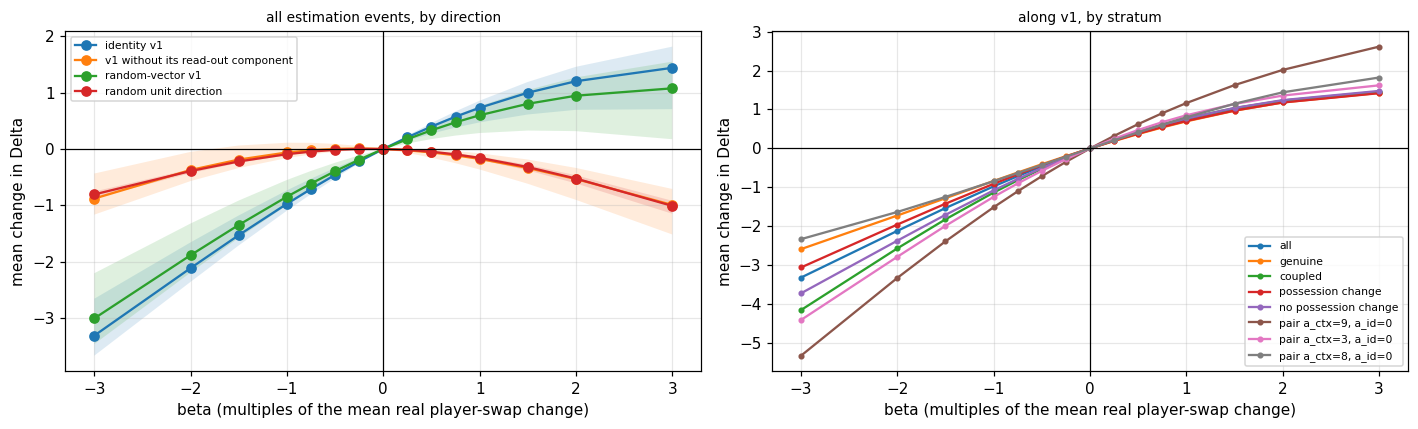

In [14]:
def curve_summary(block):
    y = block.set_index("beta (identity units)")["mean change in Delta"]
    return {"slope at 0": float((y[0.25] - y[-0.25]) / 0.5), "y(-3)": float(y[-3.0]), "y(+3)": float(y[3.0]),
            "asymmetry |y(+3)| / |y(-3)|": float(abs(y[3.0]) / abs(y[-3.0])) if y[-3.0] != 0 else np.nan,
            "monotone": bool(np.all(np.diff(y.sort_index().to_numpy()) >= 0) or np.all(np.diff(y.sort_index().to_numpy()) <= 0))}


summary_rows = []
for (half_name, direction, stratum), block in curves.groupby(["half", "direction", "stratum"]):
    summary_rows.append({"half": half_name, "direction": direction, "stratum": stratum, **curve_summary(block)})
curve_summaries = pd.DataFrame(summary_rows)
curve_summaries.to_csv(OUT / "results" / "MB16_steering_natural_summary.csv", index=False)
print(curve_summaries[curve_summaries.half == "estimation"].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in DIRECTIONS_NAT:
    block = curves[(curves.half == "estimation") & (curves.direction == name) & (curves.stratum == "all")].sort_values("beta (identity units)")
    axes[0].plot(block["beta (identity units)"], block["mean change in Delta"], marker="o", label=name)
    axes[0].fill_between(block["beta (identity units)"], block["CI low"], block["CI high"], alpha=0.15)
for stratum in STEER_STRATA:
    block = curves[(curves.half == "estimation") & (curves.direction == "identity v1") & (curves.stratum == stratum)].sort_values("beta (identity units)")
    if len(block):
        axes[1].plot(block["beta (identity units)"], block["mean change in Delta"], marker=".", label=stratum)
for axis, title in zip(axes, ["all estimation events, by direction", "along v1, by stratum"]):
    axis.axhline(0, color="black", linewidth=0.8); axis.axvline(0, color="black", linewidth=0.8)
    axis.set_xlabel("beta (multiples of the mean real player-swap change)"); axis.set_ylabel("mean change in Delta")
    axis.set_title(title, fontsize=9); axis.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB16_steering_natural.png", bbox_inches="tight"); plt.show()

## 10. Which calibration model predicts held-out steering?

Three models are fitted to the **discovery-half** mean curve along v₁ and asked to predict the **estimation-half** mean at every β:

- a straight line through 0, fitted only on |β| ≤ 0.5 (the region where a linear response is plausible);
- an isotonic (monotone) fit, interpolated between grid points;
- a 4-parameter logistic, y = a / (1 + exp(−k(β − b))) + c.

A model that predicts held-out steering well is a usable description of how the network responds to the identity direction. The straight line is expected to fail far from 0, which is what MB12 found.

In [15]:
def logistic(beta, a, k, b, c):
    return a / (1 + np.exp(-k * (beta - b))) + c


fit_block = curves[(curves.half == "discovery") & (curves.direction == "identity v1") & (curves.stratum == "all")].sort_values("beta (identity units)")
test_block = curves[(curves.half == "estimation") & (curves.direction == "identity v1") & (curves.stratum == "all")].sort_values("beta (identity units)")
x_fit, y_fit = fit_block["beta (identity units)"].to_numpy(), fit_block["mean change in Delta"].to_numpy()
near = np.abs(x_fit) <= 0.5
slope_line = float((x_fit[near] @ y_fit[near]) / (x_fit[near] @ x_fit[near]))
increasing = y_fit[-1] >= y_fit[0]
isotonic = IsotonicRegression(increasing=bool(increasing), out_of_bounds="clip").fit(x_fit, y_fit)
try:
    span = float(y_fit.max() - y_fit.min()) or 1.0
    parameters, _ = curve_fit(logistic, x_fit, y_fit, p0=[span if increasing else -span, 1.0, 0.0, float(y_fit.min() if increasing else y_fit.max())],
                              maxfev=20000)
    logistic_prediction = lambda b: logistic(b, *parameters)
except RuntimeError:
    parameters, logistic_prediction = None, lambda b: np.full_like(np.asarray(b, dtype=float), np.nan)
models = {"straight line through 0 (|beta| <= 0.5)": lambda b: slope_line * np.asarray(b),
          "isotonic": lambda b: isotonic.predict(np.asarray(b, dtype=float)), "logistic": logistic_prediction}
prediction_rows = []
for model_name, predict in models.items():
    predicted = predict(test_block["beta (identity units)"].to_numpy())
    observed = test_block["mean change in Delta"].to_numpy()
    inside = (test_block["CI low"].to_numpy() <= predicted) & (predicted <= test_block["CI high"].to_numpy())
    prediction_rows.append({"calibration model": model_name, "RMSE over the grid": float(np.sqrt(np.nanmean((predicted - observed) ** 2))),
                            "largest error": float(np.nanmax(np.abs(predicted - observed))),
                            "share of grid points inside the estimation interval": float(inside.mean())})
steering_models = pd.DataFrame(prediction_rows)
steering_models.to_csv(OUT / "results" / "MB16_steering_models.csv", index=False)
print(steering_models.round(4).to_string(index=False))
print("logistic parameters (a, k, b, c):", None if parameters is None else np.round(parameters, 4).tolist())

                      calibration model  RMSE over the grid  largest error  share of grid points inside the estimation interval
straight line through 0 (|beta| <= 0.5)              0.4223         1.2836                                               0.6667
                               isotonic              0.0532         0.0931                                               1.0000
                               logistic              0.0547         0.1223                                               0.9333
logistic parameters (a, k, b, c): [8.0236, 0.6085, -1.8704, -6.0658]


In [16]:
extension_summary = {"plan": "MB16_ext", "wrong_class": wrong_class.to_dict(orient="records"),
                     "identity_unit": IDENTITY_UNIT, "residual_norm": RESIDUAL_NORM,
                     "real_swap_along_v1_identity_units": {"median": float(np.median(projection)), "p90": float(np.percentile(projection, 90))},
                     "steering_summaries": curve_summaries.to_dict(orient="records"),
                     "steering_models": steering_models.to_dict(orient="records"), "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB16_ext_summary.json", extension_summary)
fingerprint.record_files(MANIFEST, {"results/MB16_ext_summary.json": OUT / "results" / "MB16_ext_summary.json"})

{'artifacts/conflict/conflict_set.parquet': {'path': 'artifacts/conflict/conflict_set.parquet',
  'bytes': 1735548,
  'sha256': '19d6197298f38803450ba3befbc0e1b744b6ab900eecb0f6374783c4cf2263b3',
  'recorded_at': '2026-10-05T17:22:56.743259+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt',
  'bytes': 330757,
  'sha256': '590fbc131586f5297fcd9ddfcdf7f2e1c503cf13e9f584142a5c31a10a79339c',
  'recorded_at': '2026-10-05T17:22:56.743711+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt',
  'bytes': 2280753,
  'sha256': 'eab81928ab7743ddbe2cbdb1dc60d5b584408386e896705115145e7c8a6d62a2',
  'recorded_at': '2026-10-05T17:22:56.746435+00:00'},
 'artifacts/conflict/predictions/test_probs.parquet': {'path': 'artifacts/conflict/predictions/test_probs.parquet',
  'bytes': 7982855,
  'sha256': 'd21c146acd76ee17cb82670b

## 11. Summary and integrity

In [17]:
summary = {"status": PLAN["status"], "scrub": scrub.to_dict(orient="records"), "scrub_comparisons": comparisons.to_dict(orient="records"),
           "geometry": geometry, "identity_variance_top4": float(identity_share[:4].sum()),
           "random_vector_variance_top4": float(random_share[:4].sum()),
           "steering": steering.to_dict(orient="records"), "steering_calibration": steering_calibration.to_dict(orient="records"),
           "run_mode": RUN_MODE}
mi_setup.save_json(OUT / "results" / "MB16_summary.json", summary)
fingerprint.record_files(MANIFEST, {"results/MB16_summary.json": OUT / "results" / "MB16_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB16", "experiment": "corrected causal scrub, steering geometry, calibration",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
primary = scrub[scrub.events == "events fully scrubbed under H1"]
for behaviour in behaviours:
    h1 = primary[(primary.behaviour == behaviour) & (primary.scrub == "H1 shared chain")].iloc[0]
    control = primary[(primary.behaviour == behaviour) & (primary.scrub == "H1 with permuted labels")].iloc[0]
    print(f"{behaviour}: H1 {h1['recovered share']:.3f} [{h1['CI low']:.3f}, {h1['CI high']:.3f}] vs permuted "
          f"{control['recovered share']:.3f} [{control['CI low']:.3f}, {control['CI high']:.3f}] -> supported: {h1['CI low'] > control['CI high']}")
coarse = scrub[scrub.events == "all estimation events"]
for behaviour in behaviours:
    h1c = coarse[(coarse.behaviour == behaviour) & (coarse.scrub == "H1c shared chain, coarse")].iloc[0]
    control = coarse[(coarse.behaviour == behaviour) & (coarse.scrub == "H1c with permuted labels")].iloc[0]
    h2c = coarse[(coarse.behaviour == behaviour) & (coarse.scrub == "H2c player-blind chain, coarse")].iloc[0]
    print(f"{behaviour} (coarse, all events): H1c {h1c['recovered share']:.3f} [{h1c['CI low']:.3f}, {h1c['CI high']:.3f}] | "
          f"H2c {h2c['recovered share']:.3f} | permuted {control['recovered share']:.3f} [{control['CI low']:.3f}, {control['CI high']:.3f}] "
          f"-> supported: {h1c['CI low'] > control['CI high']}")
print(f"events fully scrubbed under H1: {int(COMMON.sum())} (read the fine pair as underpowered below about 200)")

identity effect: H1 1.021 [0.933, 1.087] vs permuted 1.005 [0.845, 1.117] -> supported: False
arbitration: H1 0.912 [0.882, 0.944] vs permuted -0.035 [-0.101, 0.047] -> supported: True
identity effect (coarse, all events): H1c 0.852 [0.716, 1.026] | H2c 0.989 | permuted 0.976 [0.889, 1.105] -> supported: False
arbitration (coarse, all events): H1c 0.634 [0.555, 0.695] | H2c 0.581 | permuted -0.024 [-0.080, 0.017] -> supported: True
events fully scrubbed under H1: 311 (read the fine pair as underpowered below about 200)


In [18]:
verified_at_end = fingerprint.verify_files(MANIFEST)
manifest_after = {name: entry["sha256"] for name, entry in fingerprint.load_manifest(MANIFEST).items()}
changed = sorted(name for name in manifest_before if manifest_after.get(name) != manifest_before[name])
print(f"manifest entries verified at the end: {len(verified_at_end)}")
print("earlier entries whose fingerprint changed during this notebook:", changed if changed else "none")
assert not changed, "BLOCKED: an earlier Track B file changed while this notebook ran."
test_log = OUT / "logs" / "test_access_log.jsonl"
test_lines = len(test_log.read_text().strip().splitlines()) if test_log.exists() and test_log.read_text().strip() else 0
print(f"test accesses recorded so far: {test_lines} (MB12 recorded exactly one; this notebook adds none)")

manifest entries verified at the end: 90
earlier entries whose fingerprint changed during this notebook: none
test accesses recorded so far: 1 (MB12 recorded exactly one; this notebook adds none)


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:
- Evidence label:

## R. Corrections (REPAIR 2026-10-04)

### R1 — Demonstrating F25 with MB16's own scrub

Two independent draws of MB16's floor (every component free, independent donors per run). If the per-event floor were a stable
baseline, the second draw scored against the first would recover about 0. A value near 1 means sign alignment is picking up
noise.

In [19]:
import importlib
try:
    import mi_src.scrub as scrub
    import mi_src.steering as steering
    import mi_src.context_edits as context_edits
    import mi_src.graph as graph
except ModuleNotFoundError as error:
    raise RuntimeError("BLOCKED: the repaired modules (scrub, steering, context_edits, graph) are missing. Run "
                       "MB07R_repaired_sources_and_regression_tests.ipynb, then restart the kernel.") from error
for module in [hooks, mi_metrics, circuits, scrub, steering, context_edits, graph]:
    importlib.reload(module)
for module in [circuits, mi_metrics, scrub, steering, context_edits, graph]:
    if getattr(module, "REPAIR_VERSION", None) != "2026-10-04":
        raise RuntimeError(f"BLOCKED: {module.__name__} on disk is not the repaired 2026-10-04 version. Re-run the repaired "
                           "%%writefile cells (MB02 for mi_metrics, MB07 for circuits, MB07R for the new modules), then restart.")
print("repaired modules loaded:", [m.__name__ for m in [circuits, mi_metrics, scrub, steering, context_edits, graph]])

floor_b = run_scrub(SPECS["floor (everything free)"], estimation, DRAWS, seed=999)
floor_a = results["floor (everything free)"]
noise_mb16 = scrub.recovery_noise_check(floor_a[0] - floor_a[1], floor_b[0] - floor_b[1], full_recorded - full_removed, matches, N_BOOT)
print("MB16 design (independent per-run donors):", {k: round(v, 4) for k, v in noise_mb16.items()})

repaired modules loaded: ['mi_src.circuits', 'mi_src.mi_metrics', 'mi_src.scrub', 'mi_src.steering', 'mi_src.context_edits', 'mi_src.graph']


MB16 design (independent per-run donors): {'recovered share of floor draw 2 vs floor draw 1': 0.8588, 'CI low': 0.7981, 'CI high': 0.9426, 'SD of floor draw difference': 3.1616, 'mean |full - floor|': 1.9826}


### R2 — MB16's other hypotheses with paired counterfactual donors

H1, H2 and H3 (fine keys) are run in **MB11b Section R5** with the same corrected scrub. Here: the coarse pair (H1c, H2c) and
"H1 + a_ctx, a_id keys", each with its permuted-label control (complete label tuples permuted, scoring table untouched), plus
the paired floor and its noise check. Reading rule (MB16's own): supported only if the CI lies above the control's CI.

In [20]:
def remove_identity(inputs, positions):
    return interventions.remove_feature(inputs, IDENTITY, positions)


def paired(spec, seed, **options):
    clean, counter, _ = scrub.averaged_scrub(MODEL, bundle, val_view, estimation, spec, remove_identity, IDENTITY, DRAWS, seed, BATCH, True, **options)
    return clean, counter


paired_floor = paired({c: None for c in ALL}, 500)
paired_floor_b = paired({c: None for c in ALL}, 501)
noise_paired = scrub.recovery_noise_check(paired_floor[0] - paired_floor[1], paired_floor_b[0] - paired_floor_b[1], full_recorded - full_removed, matches, N_BOOT)
print("paired design noise check:", {k: round(v, 4) for k, v in noise_paired.items()})
specs_r = {"H1c shared chain, coarse": SPECS["H1c shared chain, coarse"], "H2c player-blind chain, coarse": SPECS["H2c player-blind chain, coarse"],
           "H1 + a_ctx, a_id keys": {**{c: KEYS_FULL + ["a_ctx", "a_id"] for c in MLPS}, **{c: None for c in HEADS}}}
rows_r = []
for index, (name, spec) in enumerate(specs_r.items()):
    for variant, options in [("right class", {}), ("permuted labels", {"wrong_class": True})]:
        clean, counter = paired(spec, 510 + 2 * index + (variant != "right class"), **options)
        for behaviour, pick in behaviours.items():
            share = scrub.recovered_share(pick(clean, counter), pick(full_recorded, full_removed), pick(*paired_floor), matches, N_BOOT)
            rows_r.append({"hypothesis": name, "donors": variant, "behaviour": behaviour, "recovered share": share["recovery"],
                           "CI low": share["ci_low"], "CI high": share["ci_high"], "mean value": float(pick(clean, counter).mean())})
scrub_paired = pd.DataFrame(rows_r)
scrub_paired.to_csv(OUT / "results" / "MB16_scrub_paired_corrected.csv", index=False)
print(scrub_paired.round(4).to_string(index=False))

paired design noise check: {'recovered share of floor draw 2 vs floor draw 1': -0.0002, 'CI low': -0.0046, 'CI high': 0.0041, 'SD of floor draw difference': 0.0154, 'mean |full - floor|': 0.4572}


                    hypothesis          donors       behaviour  recovered share  CI low  CI high  mean value
      H1c shared chain, coarse     right class identity effect           0.6250  0.4869   0.7271     -0.1335
      H1c shared chain, coarse     right class     arbitration           0.6141  0.5246   0.6832      3.4984
      H1c shared chain, coarse permuted labels identity effect           0.0516 -0.0092   0.1046     -0.0711
      H1c shared chain, coarse permuted labels     arbitration           0.0432  0.0106   0.0715     -0.1695
H2c player-blind chain, coarse     right class identity effect          -0.0006 -0.0099   0.0092     -0.0133
H2c player-blind chain, coarse     right class     arbitration           0.6068  0.5548   0.6501      3.4421
H2c player-blind chain, coarse permuted labels identity effect           0.0001 -0.0049   0.0052     -0.0091
H2c player-blind chain, coarse permuted labels     arbitration           0.0064 -0.0188   0.0399     -0.3838
         H1 + a_ctx

### R3 — Section 5's steering with a frozen, batch-invariant scale (F06)

In [21]:
SCALE = steering.reference_scale(MODEL, bundle, val_view, discovery, FINAL_SITE, BATCH)
rows_s = []
for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
    for name, direction in DIRECTIONS.items():
        changes = steering.steer_changes(MODEL, bundle, val_view, table, direction, sorted(set(BETAS) | {0.0}), SCALE, FINAL_SITE, BATCH)
        assert float(np.abs(changes[0.0]).max()) == 0.0
        betas_sorted, means, lows, highs = steering.curve(changes, table["match_id"].to_numpy(), N_BOOT)
        rows_s += [{"half": half_name, "direction": name, "beta": b, "mean change in delta": m, "CI low": lo, "CI high": hi}
                   for b, m, lo, hi in zip(betas_sorted, means, lows, highs)]
steering_corrected = pd.DataFrame(rows_s)
steering_corrected.to_csv(OUT / "results" / "MB16_steering_corrected.csv", index=False)
print(f"frozen scale (discovery mean final-residual norm): {SCALE:.4f}")
print(steering_corrected[steering_corrected.half == "estimation"].pivot(index="beta", columns="direction", values="mean change in delta").round(3).to_string())
mi_setup.save_json(OUT / "results" / "MB16_summary_corrected.json", {
    "status": "REPAIR 2026-10-04: F25 (identity-effect recovery under independent per-run donors is noise alignment) and F06",
    "noise_check_mb16_design": noise_mb16, "noise_check_paired_design": noise_paired,
    "scrub_paired": scrub_paired.to_dict(orient="records"), "steering_scale": SCALE,
    "steering": steering_corrected.to_dict(orient="records"), "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB16_summary_corrected.json": OUT / "results" / "MB16_summary_corrected.json"})
fingerprint.register(REGISTRY, {"notebook": "MB16", "experiment": "R: F25 noise check, paired scrub of coarse hypotheses, F06 steering", "seed": PRIMARY_SEED, "run_mode": RUN_MODE})

frozen scale (discovery mean final-residual norm): 5.0195
direction  identity v1  identity v1 without its read-out component  random-vector v1  read-out direction g_hat
beta                                                                                                          
-2.00           -8.475                                      -4.363            -7.876                   -10.907
-1.50           -7.362                                      -3.477            -6.830                    -9.666
-1.00           -5.491                                      -2.136            -5.073                    -7.631
-0.50           -2.722                                      -0.610            -2.451                    -4.332
-0.25           -1.250                                      -0.118            -1.095                    -2.204
 0.00            0.000                                       0.000             0.000                     0.000
 0.25            0.875                                

**Reading.** If R1's MB16-design noise check is near 1 and the paired one near 0, F25 is confirmed on the real model, and only
the paired results (here and in MB11b R5) can be read for the identity effect. MB16's arbitration results, geometry (Section 5,
cosines) and natural-unit steering (Sections 9–10) are not affected by F25.

**Researcher interpretation of Section R** *(to be written after reading the numbers)*

- What was observed:
- What it supports / contradicts:
- What it does not establish: